# V5 — GPU Data Residency (kế thừa V4: V2 S4 + V3 S6 crop + V4 S6 warp)

V5 kế thừa toàn bộ kernel tính toán của **V4** (V1 S1–S3/S5, V2 S4 shared-memory descriptor tiling, V3 S6 compressed crop stack, V4 S6 `warp_blend`), và **chỉ thay đổi đường đi dữ liệu**:
- Upload ảnh `A, B` lên GPU **1 lần** ở đầu pipeline và dùng lại ở S6.
- Giữ toàn bộ buffer trung gian (`gray`, `blur`, `response`, `keypoints`, `descriptors`, `matches`, `V5HomographyResult H`) trên device memory xuyên suốt S1→S6.
- Chỉ copy metadata điều phối và ảnh `panorama` cuối cùng về host.

Chọn Colab **GPU**, rồi **Run all**. Chốt hiệu quả V5 sau parity (V0/V4), đo 12 case (`transfer_bytes`, `h2d`, `d2h`, `residual`, `end_to_end`) và Nsight Systems (`cuda_gpu_mem_time_sum`, `cuda_api_sum`, `cuda_gpu_kern_sum`).

In [1]:
from pathlib import Path
import csv
import datetime
import json
import os
import shlex
import shutil
import subprocess
import sys
from statistics import geometric_mean

REPO_URL = "https://github.com/nganbee/panorama-stitching-project.git"
BRANCH = "v5"
REPO = Path("/content/panorama-stitching-project")
UPDATE_REPO = True  # False: giữ source đã upload/chỉnh tại Colab.
RUNS = 5
RUN_PROFILER = True
COMMAND_LOG_DIR = None
COMMAND_INDEX = 0

def run(args, check=True, log=None):
    global COMMAND_INDEX
    command = shlex.join([str(a) for a in args])
    print("$", command, flush=True)
    if log is None and COMMAND_LOG_DIR is not None:
        COMMAND_INDEX += 1
        log = COMMAND_LOG_DIR / f"command_{COMMAND_INDEX:03d}.log"
    stream = None
    try:
        if log is not None:
            log = Path(log)
            log.parent.mkdir(parents=True, exist_ok=True)
            stream = log.open("w", encoding="utf-8")
            stream.write("$ " + command + "\n")
        with subprocess.Popen([str(a) for a in args], text=True,
                              stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                              bufsize=1) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                if stream is not None:
                    stream.write(line)
                    stream.flush()
            code_ret = process.wait()
    finally:
        if stream is not None:
            stream.close()
    if check and code_ret:
        raise RuntimeError(f"Command failed ({code_ret}); log: {log}")
    return code_ret

if not REPO.exists():
    run(["git", "clone", "--branch", BRANCH, REPO_URL, REPO])
os.chdir(REPO)
if UPDATE_REPO:
    dirty = subprocess.check_output(["git", "status", "--porcelain"], text=True).strip()
    if dirty:
        print("Có thay đổi local: giữ nguyên checkout, không tự pull.")
    else:
        run(["git", "fetch", "origin", BRANCH])
        run(["git", "checkout", BRANCH])
        run(["git", "merge", "--ff-only", f"origin/{BRANCH}"])

required = [
    "src/stage_implementations/v2_stage4.cu",
    "src/stage_implementations/v3_stage6.cu",
    "src/stage_implementations/v4_stage6.cu",
    "src/stage_implementations/v5_stage4.cu",
    "src/stage_implementations/v5_stage6.cu",
    "src/cuda/v5_pipeline.cu",
]
assert all(Path(p).is_file() for p in required), "Thiếu source V2/V3/V4/V5 tích lũy."
assert RUNS >= 5
STAMP = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
SESSION_DIR = Path("out") / f"v5_inspect_{STAMP}"
SESSION_DIR.mkdir(parents=True)
COMMAND_LOG_DIR = SESSION_DIR / "commands"
RESULTS = SESSION_DIR / "benchmark"
RESULTS.mkdir(parents=True)
Path("build").mkdir(exist_ok=True)
run(["git", "status", "--short"])
run(["git", "branch", "--show-current"])
run(["git", "rev-parse", "HEAD"])
print("Session:", SESSION_DIR)

$ git clone --branch v5 https://github.com/nganbee/panorama-stitching-project.git /content/panorama-stitching-project
Cloning into '/content/panorama-stitching-project'...
$ git fetch origin v5
From https://github.com/nganbee/panorama-stitching-project
 * branch            v5         -> FETCH_HEAD
$ git checkout v5
Already on 'v5'
Your branch is up to date with 'origin/v5'.
$ git merge --ff-only origin/v5
Already up to date.
$ git status --short
$ git branch --show-current
v5
$ git rev-parse HEAD
2c37391458b8de555eb71ed9303983bd28076086
Session: out/v5_inspect_20261124T121909_588797Z


## 1. GPU, compiler và build chung (V0–V5)

Giữ `--fmad=false`, không dùng fast math. Một binary `build/stitch_v5` cung cấp V0/V1/V2/V3/V4/V5 với cùng input, flags và GPU session.

In [2]:
run(["nvidia-smi"], log=SESSION_DIR / "nvidia-smi.log")
GPU = subprocess.check_output(["nvidia-smi", "--query-gpu=name,uuid,driver_version",
                               "--format=csv,noheader"], text=True).strip()
print("GPU:", GPU)
run(["nvcc", "--version"])
FLAGS = [
    "nvcc", "-O2", "-std=c++17", "--fmad=false",
    "-DPANORAMA_WITH_CUDA", "-DPANORAMA_WITH_V2", "-DPANORAMA_WITH_V3",
    "-DPANORAMA_WITH_V4", "-DPANORAMA_WITH_V5",
    "-Isrc/core_headers", "-Isrc/libraries",
]
SOURCES = [
    "src/integration/v0_pipeline.cpp",
    "src/stage_implementations/v0_stage12.cpp",
    "src/stage_implementations/v0_stage34.cpp",
    "src/stage_implementations/v0_stage5.cpp",
    "src/stage_implementations/v0_stage6.cpp",
    "src/stage_implementations/v1_stage12.cu",
    "src/stage_implementations/v1_stage34.cu",
    "src/stage_implementations/v1_stage5.cu",
    "src/stage_implementations/v1_stage6.cu",
    "src/stage_implementations/v2_stage4.cu",
    "src/stage_implementations/v3_stage6.cu",
    "src/stage_implementations/v4_stage6.cu",
    "src/stage_implementations/v5_stage4.cu",
    "src/stage_implementations/v5_stage6.cu",
    "src/cuda/cuda_pipeline.cu",
    "src/cuda/v2_pipeline.cu",
    "src/cuda/v3_pipeline.cu",
    "src/cuda/v4_pipeline.cu",
    "src/cuda/v5_pipeline.cu",
    "src/libraries/stb_impl.cpp",
]
run(FLAGS + ["src/integration/main.cpp"] + SOURCES + ["-o", "build/stitch_v5"])
run(["build/stitch_v5", "--list-versions"])
run(["build/stitch_v5", "--dump-params"])
(SESSION_DIR / "environment.json").write_text(json.dumps({
    "gpu": GPU,
    "commit": subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip(),
    "flags": FLAGS,
    "runs": RUNS,
    "warmup_runs": 1,
}, indent=2), encoding="utf-8")

$ nvidia-smi
Tue Nov 24 12:19:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------------------

424

## 2. Parity V5 vs V0/V4 & kiểm tra giảm `h2d_bytes` / `d2h_bytes`

`test_v5_pipeline` kiểm tra:
- S1–S6 của V5 khớp bit-identical với V4 và đạt dung sai PLAN so với V0.
- `h2d_bytes == A.size + B.size` (chỉ upload 2 ảnh nguồn 1 lần) và nhỏ hơn hẳn V1/V4.
- `d2h_bytes` nhỏ hơn hẳn V1/V4.

In [3]:
run(FLAGS + ["src/tools/v5/test_v5_pipeline.cpp"] + SOURCES + ["-o", "build/test_v5_pipeline"])
run(["build/test_v5_pipeline"])
run(["build/stitch_v5", "--selftest", "--version", "5"])

$ nvcc -O2 -std=c++17 --fmad=false -DPANORAMA_WITH_CUDA -DPANORAMA_WITH_V2 -DPANORAMA_WITH_V3 -DPANORAMA_WITH_V4 -DPANORAMA_WITH_V5 -Isrc/core_headers -Isrc/libraries src/tools/v5/test_v5_pipeline.cpp src/integration/v0_pipeline.cpp src/stage_implementations/v0_stage12.cpp src/stage_implementations/v0_stage34.cpp src/stage_implementations/v0_stage5.cpp src/stage_implementations/v0_stage6.cpp src/stage_implementations/v1_stage12.cu src/stage_implementations/v1_stage34.cu src/stage_implementations/v1_stage5.cu src/stage_implementations/v1_stage6.cu src/stage_implementations/v2_stage4.cu src/stage_implementations/v3_stage6.cu src/stage_implementations/v4_stage6.cu src/stage_implementations/v5_stage4.cu src/stage_implementations/v5_stage6.cu src/cuda/cuda_pipeline.cu src/cuda/v2_pipeline.cu src/cuda/v3_pipeline.cu src/cuda/v4_pipeline.cu src/cuda/v5_pipeline.cu src/libraries/stb_impl.cpp -o build/test_v5_pipeline
$ build/test_v5_pipeline
  panorama MAE vs V0=0.000000000
PASS: V5 vs V0/V4 (

0

## 3. Compute Sanitizer (`memcheck`)

In [4]:
if shutil.which("compute-sanitizer"):
    run(["compute-sanitizer", "--tool", "memcheck", "--error-exitcode", "1", "build/test_v5_pipeline"])
else:
    print("NOT RUN: Compute Sanitizer unavailable.")

$ compute-sanitizer --tool memcheck --error-exitcode 1 build/test_v5_pipeline
========= COMPUTE-SANITIZER
  panorama MAE vs V0=0.000000000
PASS: V5 vs V0/V4 (193x157 + 193x157, matches=287 inliers=287)
  bytes H2D V1=1368832 V4=1368832 V5=181806 | D2H V1=847039 V4=847039 V5=91115
  ms H2D V4=0.729 V5=0.074 | D2H V4=1.118 V5=0.634 | E2E V4=185.342 V5=181.501
  panorama MAE vs V0=0.000000000
PASS: V5 vs V0/V4 (193x157 + 193x157, matches=268 inliers=268)
  bytes H2D V1=1368492 V4=1368492 V5=181806 | D2H V1=852375 V4=852375 V5=96767
  ms H2D V4=0.658 V5=0.075 | D2H V4=1.202 V5=0.628 | E2E V4=179.852 V5=176.639
  panorama MAE vs V0=0.000000000
PASS: V5 vs V0/V4 (193x157 + 193x157, matches=287 inliers=287)
  bytes H2D V1=1368832 V4=1368832 V5=181806 | D2H V1=847039 V4=847039 V5=91115
  ms H2D V4=0.660 V5=0.119 | D2H V4=1.096 V5=0.702 | E2E V4=182.580 V5=179.442
PASS: V5 expected error cases
========= ERROR SUMMARY: 0 errors


## 4. Baseline V4 trên 4K: xác nhận tỷ trọng H2D/D2H và residual trước khi đo V5

In [5]:
BASELINE = SESSION_DIR / "v4_baseline.json"
LEFT = "dataset/location1/large_4k/1.jpg"
RIGHT = "dataset/location1/large_4k/2.jpg"
run(["build/stitch_v5", LEFT, RIGHT, SESSION_DIR / "v4_baseline.png",
     "--version", "4", "--runs", RUNS, "--json", BASELINE], log=SESSION_DIR / "v4_baseline.log")
b4 = json.loads(BASELINE.read_text(encoding="utf-8"))
t4 = b4["timings_ms"]
tb4 = b4["transfer_bytes"]
res4 = t4["end_to_end"] - t4["kernel_total"] - t4["h2d"] - t4["d2h"]
print(f"V4 4K: kernel={t4['kernel_total']:.2f} ms | h2d={t4['h2d']:.2f} ms | d2h={t4['d2h']:.2f} ms | residual={res4:.2f} ms | E2E={t4['end_to_end']:.2f} ms")
print(f"V4 4K transfer_bytes: H2D={tb4['h2d']/1e6:.2f} MB | D2H={tb4['d2h']/1e6:.2f} MB")

$ build/stitch_v5 dataset/location1/large_4k/1.jpg dataset/location1/large_4k/2.jpg out/v5_inspect_20261124T121909_588797Z/v4_baseline.png --version 4 --runs 5 --json out/v5_inspect_20261124T121909_588797Z/v4_baseline.json
version=4 runs=5 imageA=3840x2160 imageB=3840x2160
keypoints_A=3000 keypoints_B=3000 matches=1393 inliers=865
panorama=9088x2160 inlier_ratio=0.621
avg_ms gray=0.501 blur=1.339 harris=4.059 nms_topk=1.316 describe=0.534 match=0.635 ransac=12.657 warp_blend=32.438 h2d=82.070 d2h=54.337 kernel_total=53.479 end_to_end=341.344
avg_bytes h2d=365306316 d2h=258236768
V4 4K: kernel=53.48 ms | h2d=82.07 ms | d2h=54.34 ms | residual=151.46 ms | E2E=341.34 ms
V4 4K transfer_bytes: H2D=365.31 MB | D2H=258.24 MB


## 5. Benchmark V0 / V4 / V5 trên đủ 12 cặp ảnh

Mỗi case chạy parity thật (`build/test_v5_pipeline <left> <right>`), sau đó đo V0, V4, V5 (đảo thứ tự V4/V5 xen kẽ theo scene, mỗi lần 1 warm-up + `RUNS` timed runs).

In [6]:
SCENES = ["location1", "location2", "location3", "challenge"]
RESOLUTIONS = [("720p", "small_720p"), ("1080p", "medium_1080p"), ("4k", "large_4k")]

summary_rows = []
timing_rows = []

for scene_idx, scene in enumerate(SCENES):
    for res_label, folder in RESOLUTIONS:
        case = f"{scene}_{res_label}"
        left = Path("dataset") / scene / folder / "1.jpg"
        right = Path("dataset") / scene / folder / "2.jpg"
        print(f"\n=== CASE {case} ===", flush=True)
        if not left.is_file() or not right.is_file():
            summary_rows.append({"case": case, "status": "failed", "parity": "missing_dataset"})
            continue
        p_code = run(["build/test_v5_pipeline", left, right], check=False, log=RESULTS / f"{case}_parity.log")
        parity_status = "pass" if p_code == 0 else "failed"
        order = (0, 5, 4) if (scene_idx % 2) else (0, 4, 5)
        reports = {}
        ok = (p_code == 0)
        for v in order:
            r_path = RESULTS / f"{case}_v{v}.json"
            c_ret = run(["build/stitch_v5", left, right, RESULTS / f"{case}_v{v}.png",
                         "--version", v, "--runs", RUNS, "--json", r_path],
                        check=False, log=RESULTS / f"{case}_v{v}.log")
            if c_ret != 0 or not r_path.is_file():
                ok = False
                continue
            rep = json.loads(r_path.read_text(encoding="utf-8"))
            reports[v] = rep
            t = rep["timings_ms"]
            tb = rep.get("transfer_bytes", {"h2d": 0.0, "d2h": 0.0})
            residual = (t["end_to_end"] - t["kernel_total"] - t["h2d"] - t["d2h"]) if v in (4, 5) else float("nan")
            timing_rows.append({
                "case": case, "scene": scene, "resolution": res_label, "version": v,
                "status": rep.get("status", "ok"), "parity": parity_status,
                **t, "h2d_bytes": tb["h2d"], "d2h_bytes": tb["d2h"], "residual_ms": residual,
            })
        if len(reports) == 3:
            t0, t4, t5 = [reports[v]["timings_ms"] for v in (0, 4, 5)]
            b4, b5 = [reports[v].get("transfer_bytes", {"h2d": 0.0, "d2h": 0.0}) for v in (4, 5)]
            summary_rows.append({
                "case": case, "resolution": res_label, "status": "ok" if ok else "failed", "parity": parity_status,
                "v4_h2d_mb": b4["h2d"] / 1e6, "v5_h2d_mb": b5["h2d"] / 1e6,
                "v4_d2h_mb": b4["d2h"] / 1e6, "v5_d2h_mb": b5["d2h"] / 1e6,
                "v4_h2d_ms": t4["h2d"], "v5_h2d_ms": t5["h2d"],
                "v4_d2h_ms": t4["d2h"], "v5_d2h_ms": t5["d2h"],
                "v4_kernel_ms": t4["kernel_total"], "v5_kernel_ms": t5["kernel_total"],
                "v4_residual_ms": t4["end_to_end"] - t4["kernel_total"] - t4["h2d"] - t4["d2h"],
                "v5_residual_ms": t5["end_to_end"] - t5["kernel_total"] - t5["h2d"] - t5["d2h"],
                "v0_e2e_ms": t0["end_to_end"], "v4_e2e_ms": t4["end_to_end"], "v5_e2e_ms": t5["end_to_end"],
                "e2e_speedup_v4_v5": t4["end_to_end"] / t5["end_to_end"],
                "e2e_speedup_v0_v5": t0["end_to_end"] / t5["end_to_end"],
            })
        else:
            summary_rows.append({"case": case, "resolution": res_label, "status": "failed", "parity": parity_status})

import pandas as pd
summary = pd.DataFrame(summary_rows)
timings = pd.DataFrame(timing_rows)
summary.to_csv(RESULTS / "summary.csv", index=False)
timings.to_csv(RESULTS / "timings.csv", index=False)
print("Saved:", RESULTS / "summary.csv")


=== CASE location1_720p ===
$ build/test_v5_pipeline dataset/location1/small_720p/1.jpg dataset/location1/small_720p/2.jpg
  panorama MAE vs V0=0.000002865
PASS: V5 vs V0/V4 (1280x720 + 1280x720, matches=620 inliers=448)
  bytes H2D V1=40713800 V4=40713800 V5=5529600 | D2H V1=28532032 V4=28532032 V5=6283652
  ms H2D V4=9.563 V5=1.317 | D2H V4=6.788 V5=1.505 | E2E V4=64.968 V5=39.723
$ build/stitch_v5 dataset/location1/small_720p/1.jpg dataset/location1/small_720p/2.jpg out/v5_inspect_20261124T121909_588797Z/benchmark/location1_720p_v0.png --version 0 --runs 5 --json out/v5_inspect_20261124T121909_588797Z/benchmark/location1_720p_v0.json
version=0 runs=5 imageA=1280x720 imageB=1280x720
keypoints_A=1311 keypoints_B=1474 matches=620 inliers=448
panorama=2909x720 inlier_ratio=0.723
avg_ms gray=3.408 blur=52.382 harris=71.861 nms_topk=5.878 describe=8.711 match=749.003 ransac=17.749 warp_blend=270.832 h2d=0.000 d2h=0.000 kernel_total=0.000 end_to_end=1179.827
avg_bytes h2d=0 d2h=0
$ build/

## 6. So sánh V4 vs V5: Transfer Bytes, H2D/D2H, Residual và E2E

Verified cases: 12/12
=== 6.1 So sánh dung lượng & thời gian truyền H2D/D2H ===


,case,v4_h2d_mb,v5_h2d_mb,h2d_bytes_reduction_x,v4_d2h_mb,v5_d2h_mb,d2h_bytes_reduction_x,copy_ms_v4,copy_ms_v5,copy_speedup
0,location1_720p,40.714,5.530,7.363,28.532,6.284,4.541,17.829,2.863,6.228
1,location1_1080p,91.487,12.442,7.353,64.363,14.399,4.470,36.862,6.042,6.101
2,location1_4k,365.306,49.766,7.340,258.237,58.890,4.385,142.450,27.466,5.186
3,location2_720p,40.773,5.530,7.374,27.913,5.618,4.968,16.091,2.851,5.643
4,location2_1080p,91.566,12.442,7.360,62.664,12.639,4.958,35.204,5.528,6.368
5,location2_4k,365.295,49.766,7.340,250.605,51.270,4.888,134.188,23.217,5.780
6,location3_720p,40.566,5.530,7.336,27.218,5.087,5.351,15.732,2.537,6.201
7,location3_1080p,91.285,12.442,7.337,63.149,13.346,4.732,34.480,5.665,6.086
8,location3_4k,365.135,49.766,7.337,258.546,59.338,4.357,136.342,25.551,5.336
9,challenge_720p,40.651,5.530,7.351,28.810,6.612,4.357,16.066,2.944,5.457


=== 6.2 So sánh Kernel, Residual và End-to-End ===


,case,v4_kernel_ms,v5_kernel_ms,v4_residual_ms,v5_residual_ms,v4_e2e_ms,v5_e2e_ms,e2e_speedup_v4_v5,e2e_speedup_v0_v5
0,location1_720p,19.618,15.118,24.862,7.101,62.309,25.083,2.484,47.038
1,location1_1080p,28.649,23.712,49.665,12.411,115.176,42.165,2.732,67.773
2,location1_4k,55.870,61.523,173.913,38.809,372.233,127.798,2.913,59.988
3,location2_720p,12.198,16.351,17.431,8.669,45.720,27.871,1.640,61.431
4,location2_1080p,17.315,20.989,29.720,10.947,82.240,37.464,2.195,107.207
5,location2_4k,38.757,39.626,148.769,33.982,321.714,96.826,3.323,68.042
6,location3_720p,17.863,12.875,19.998,6.431,53.592,21.843,2.454,14.730
7,location3_1080p,22.000,17.287,41.518,11.358,97.997,34.310,2.856,28.829
8,location3_4k,39.566,40.779,153.507,38.206,329.415,104.535,3.151,37.908
9,challenge_720p,12.003,18.300,16.945,8.022,45.014,29.266,1.538,24.274


=== 6.3 Geometric mean theo độ phân giải ===


,h2d_bytes_reduction_x,d2h_bytes_reduction_x,copy_speedup,e2e_speedup_v4_v5,e2e_speedup_v0_v5
resolution,,,,,
720p,7.356,4.789,5.872,1.980,31.882
1080p,7.349,4.574,5.912,2.333,50.327
4k,7.339,4.477,5.284,3.022,55.709


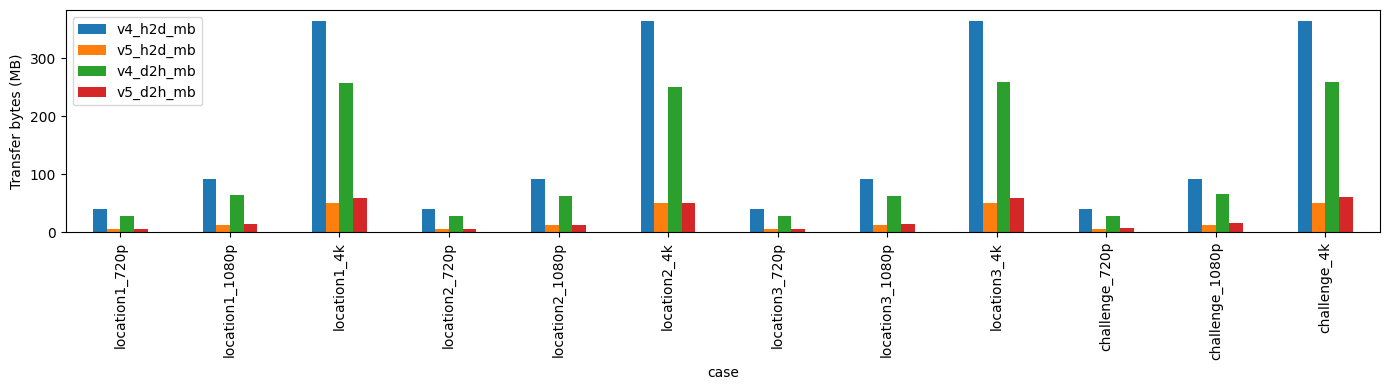

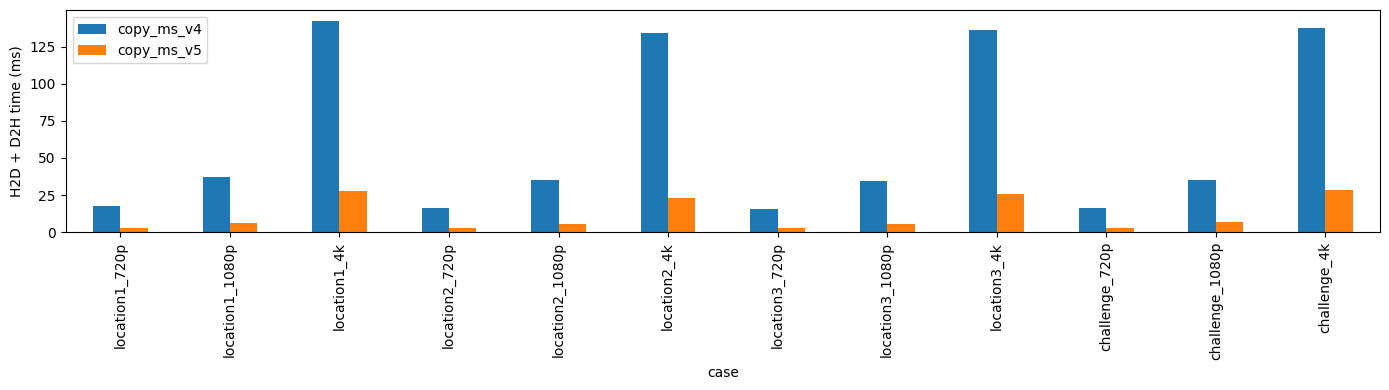

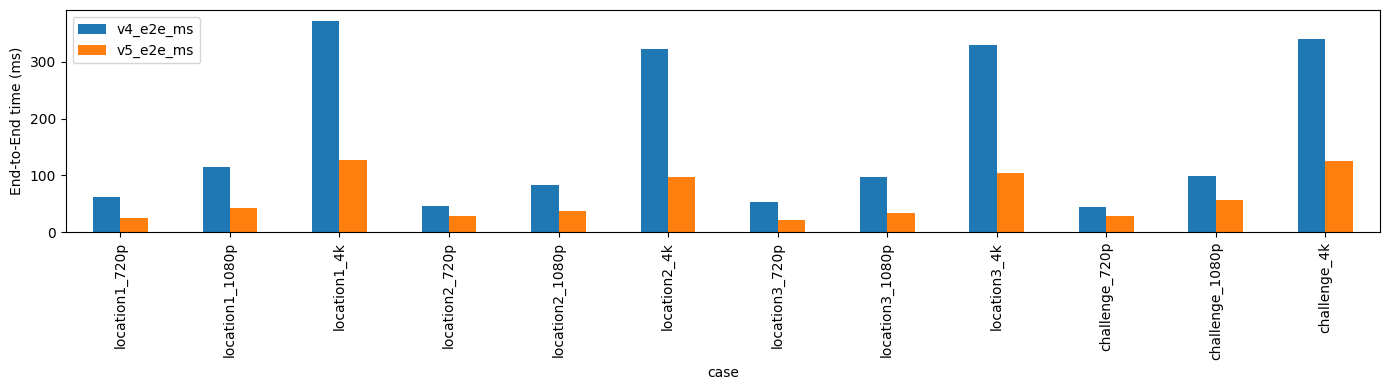

In [7]:
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
ok_sum = summary.loc[summary.status.eq("ok") & summary.parity.eq("pass")].copy()
print(f"Verified cases: {len(ok_sum)}/{len(summary)}")

ok_sum["h2d_bytes_reduction_x"] = ok_sum["v4_h2d_mb"] / ok_sum["v5_h2d_mb"].where(ok_sum["v5_h2d_mb"] > 0)
ok_sum["d2h_bytes_reduction_x"] = ok_sum["v4_d2h_mb"] / ok_sum["v5_d2h_mb"].where(ok_sum["v5_d2h_mb"] > 0)
ok_sum["copy_ms_v4"] = ok_sum["v4_h2d_ms"] + ok_sum["v4_d2h_ms"]
ok_sum["copy_ms_v5"] = ok_sum["v5_h2d_ms"] + ok_sum["v5_d2h_ms"]
ok_sum["copy_speedup"] = ok_sum["copy_ms_v4"] / ok_sum["copy_ms_v5"].where(ok_sum["copy_ms_v5"] > 0)

print("=== 6.1 So sánh dung lượng & thời gian truyền H2D/D2H ===")
display(ok_sum[["case", "v4_h2d_mb", "v5_h2d_mb", "h2d_bytes_reduction_x",
                "v4_d2h_mb", "v5_d2h_mb", "d2h_bytes_reduction_x",
                "copy_ms_v4", "copy_ms_v5", "copy_speedup"]].round(3))

print("=== 6.2 So sánh Kernel, Residual và End-to-End ===")
display(ok_sum[["case", "v4_kernel_ms", "v5_kernel_ms", "v4_residual_ms", "v5_residual_ms",
                "v4_e2e_ms", "v5_e2e_ms", "e2e_speedup_v4_v5", "e2e_speedup_v0_v5"]].round(3))

print("=== 6.3 Geometric mean theo độ phân giải ===")
by_res = ok_sum.groupby("resolution", sort=False)[["h2d_bytes_reduction_x", "d2h_bytes_reduction_x",
                                                    "copy_speedup", "e2e_speedup_v4_v5", "e2e_speedup_v0_v5"]].agg(geometric_mean)
display(by_res.round(3))

for cols, ylabel in [
    (["v4_h2d_mb", "v5_h2d_mb", "v4_d2h_mb", "v5_d2h_mb"], "Transfer bytes (MB)"),
    (["copy_ms_v4", "copy_ms_v5"], "H2D + D2H time (ms)"),
    (["v4_e2e_ms", "v5_e2e_ms"], "End-to-End time (ms)"),
]:
    ok_sum.set_index("case")[cols].plot.bar(figsize=(14, 4), ylabel=ylabel)
    plt.tight_layout()
    plt.show()

## 7. Profiler Nsight Systems (`nsys`): Memory Transfers, CUDA API & Kernels (V4 vs V5)

Tách riêng 3 report `nsys stats` (`cuda_gpu_mem_time_sum`, `cuda_api_sum`, `cuda_gpu_kern_sum`) để chứng minh:
1. Số lần gọi và tổng thời gian `cudaMemcpy` HtoD/DtoH giảm mạnh ở V5.
2. Chi phí API ngoài kernel (`cudaMalloc`/`cudaFree`/`cudaMemcpy`) thay đổi thế nào.
3. Kernel tính toán của V5 giữ nguyên từ V4 (`nearest_tiled_kernel`, `warp_blend_v4_kernel`/`warp_blend_v5_kernel`, `find_crop_rows_compressed_stack_kernel`).

In [8]:
PROFILE_DIR = SESSION_DIR / "profiles"
PROFILE_DIR.mkdir(exist_ok=True)
PROFILE_CASES = [("location1", "medium_1080p", "location1_1080p"),
                 ("location1", "large_4k", "location1_4k")]

def parse_nsys_csv(text, required_cols):
    rows, cols = [], None
    for vals in csv.reader(text.splitlines()):
        vals = [v.strip().lstrip("\ufeff") for v in vals]
        if required_cols <= set(vals):
            cols = vals
        elif cols is not None and len(vals) == len(cols):
            rows.append(dict(zip(cols, vals)))
    return rows

def profile_v4_v5(scene, folder, case, version):
    prefix = PROFILE_DIR / f"nsys_v{version}_{case}"
    left = Path("dataset") / scene / folder / "1.jpg"
    right = left.with_name("2.jpg")
    run(["nsys", "profile", "--trace=cuda", "--sample=none", "--force-overwrite=true",
         "-o", prefix, "build/stitch_v5", left, right,
         PROFILE_DIR / f"{case}_v{version}.png", "--version", version, "--runs", RUNS],
        log=prefix.with_suffix(".log"))
    rep = prefix.with_suffix(".nsys-rep")
    res = {"case": case, "version": version}
    for report_name, req_cols, key_col in [
        ("cuda_gpu_mem_time_sum", {"Total Time (ns)", "Count", "Operation"}, "Operation"),
        ("cuda_api_sum", {"Total Time (ns)", "Num Calls", "Name"}, "Name"),
        ("cuda_gpu_kern_sum", {"Total Time (ns)", "Instances", "Name"}, "Name"),
    ]:
        log_f = prefix.with_name(f"{prefix.name}_{report_name}.log")
        run(["nsys", "stats", "--force-export=true", "--report", report_name, "--format", "csv",
             "--output", "-", rep], log=log_f)
        parsed = parse_nsys_csv(log_f.read_text(encoding="utf-8"), req_cols)
        df = pd.DataFrame(parsed)
        df.to_csv(prefix.with_name(f"{prefix.name}_{report_name}.csv"), index=False)
        print(f"--- V{version} {case} [{report_name}] ---")
        display(df.head(12))
        if report_name == "cuda_gpu_mem_time_sum" and not df.empty:
            for op in ("Host-to-Device", "Device-to-Host"):
                sub = df.loc[df["Operation"].str.contains(op, case=False, na=False)]
                res[f"{op}_ms"] = sub["Total Time (ns)"].str.replace(",", "").astype(float).sum() / 1e6 / (RUNS + 1)
                res[f"{op}_calls"] = sub["Count"].str.replace(",", "").astype(int).sum() / (RUNS + 1)
        if report_name == "cuda_api_sum" and not df.empty:
            for api in ("cudaMemcpy", "cudaMalloc", "cudaFree"):
                sub = df.loc[df["Name"].str.contains(api, case=False, na=False)]
                res[f"{api}_api_ms"] = sub["Total Time (ns)"].str.replace(",", "").astype(float).sum() / 1e6 / (RUNS + 1)
                res[f"{api}_calls"] = sub["Num Calls"].str.replace(",", "").astype(int).sum() / (RUNS + 1)
    return res

if RUN_PROFILER and shutil.which("nsys"):
    prof_rows = []
    for scene, folder, case in PROFILE_CASES:
        for version in (4, 5):
            prof_rows.append(profile_v4_v5(scene, folder, case, version))
    prof_df = pd.DataFrame(prof_rows)
    prof_df.to_csv(PROFILE_DIR / "v4_vs_v5_nsys_summary.csv", index=False)
    print("=== Tóm tắt Nsight V4 vs V5 (trung bình mỗi pipeline run) ===")
    display(prof_df.round(3))
else:
    print("NOT RUN: nsys unavailable.")

$ nsys profile --trace=cuda --sample=none --force-overwrite=true -o out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v4_location1_1080p build/stitch_v5 dataset/location1/medium_1080p/1.jpg dataset/location1/medium_1080p/2.jpg out/v5_inspect_20261124T121909_588797Z/profiles/location1_1080p_v4.png --version 4 --runs 5
version=4 runs=5 imageA=1920x1080 imageB=1920x1080
keypoints_A=1956 keypoints_B=2283 matches=973 inliers=689
panorama=4444x1080 inlier_ratio=0.708
avg_ms gray=0.176 blur=0.636 harris=1.629 nms_topk=0.755 describe=0.317 match=0.686 ransac=16.305 warp_blend=12.269 h2d=21.035 d2h=14.102 kernel_total=32.772 end_to_end=103.684
avg_bytes h2d=91487460 d2h=64363364
Generating '/tmp/nsys-report-dfd0.qdstrm'

[1/1] [0%                          ] nsys_v4_location1_1080p.nsys-rep
[1/1] [0%                          ] nsys_v4_location1_1080p.nsys-rep
[1/1] [7%                          ] nsys_v4_location1_1080p.nsys-rep
[1/1] [8%                          ] nsys_v4_location1_1080p.nsys

,Time (%),Total Time (ns),Count,Avg (ns),Med (ns),Min (ns),Max (ns),StdDev (ns),Operation
0,61.3,108069854,114,947981.2,1199408.0,2144,1854510,743690.1,[CUDA memcpy Host-to-Device]
1,38.7,68225982,120,568549.8,3632.0,1248,3091597,820717.4,[CUDA memcpy Device-to-Host]
2,0.0,34559,24,1440.0,1408.0,736,1920,285.3,[CUDA memset]


$ nsys stats --force-export=true --report cuda_api_sum --format csv --output - out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v4_location1_1080p.nsys-rep
Generating SQLite file out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v4_location1_1080p.sqlite from out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v4_location1_1080p.nsys-rep
Processing [out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v4_location1_1080p.sqlite] with [/opt/nvidia/nsight-compute/2025.3.1/host/target-linux-x64/reports/cuda_api_sum.py]... 
Time (%),Total Time (ns),Num Calls,Avg (ns),Med (ns),Min (ns),Max (ns),StdDev (ns),Name
30.2,217105433,588,369226.9,12390.5,4350,13516200,1527123.5,cudaEventSynchronize
28.4,204691737,234,874751.0,32546.5,9914,3484856,912857.5,cudaMemcpy
24.7,177577969,12,14798164.1,1874.0,469,177556131,51255466.9,cudaEventCreate
12.3,88432250,438,201900.1,88432.0,2146,1470844,297887.6,cudaFree
3.1,22034992,438,50308.2,61234.5,2240,338804,43403.7,cudaMalloc
0.6,4539075,354,12822.

,Time (%),Total Time (ns),Num Calls,Avg (ns),Med (ns),Min (ns),Max (ns),StdDev (ns),Name
0,30.2,217105433,588,369226.9,12390.5,4350,13516200,1527123.5,cudaEventSynchronize
1,28.4,204691737,234,874751.0,32546.5,9914,3484856,912857.5,cudaMemcpy
2,24.7,177577969,12,14798164.1,1874.0,469,177556131,51255466.9,cudaEventCreate
3,12.3,88432250,438,201900.1,88432.0,2146,1470844,297887.6,cudaFree
4,3.1,22034992,438,50308.2,61234.5,2240,338804,43403.7,cudaMalloc
5,0.6,4539075,354,12822.2,5915.0,3878,481856,31938.0,cudaLaunchKernel
6,0.5,3765193,1176,3201.7,2227.0,1465,37348,2441.1,cudaEventRecord
7,0.1,762246,6,127041.0,130358.5,41051,213151,64218.4,cuLibraryLoadData
8,0.1,460766,252,1828.4,1135.0,982,5662,1151.6,cudaDeviceSynchronize
9,0.0,179867,24,7494.5,6899.0,5469,12652,2028.3,cudaMemset


$ nsys stats --force-export=true --report cuda_gpu_kern_sum --format csv --output - out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v4_location1_1080p.nsys-rep
Generating SQLite file out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v4_location1_1080p.sqlite from out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v4_location1_1080p.nsys-rep
Processing [out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v4_location1_1080p.sqlite] with [/opt/nvidia/nsight-compute/2025.3.1/host/target-linux-x64/reports/cuda_gpu_kern_sum.py]... 
Time (%),Total Time (ns),Instances,Avg (ns),Med (ns),Min (ns),Max (ns),StdDev (ns),Name
27.9,58134957,6,9689159.5,9437316.0,6089117,13510070,3310239.9,"<unnamed>::warp_blend_v4_kernel(const unsigned char *, int, int, const uchar4 *, int, int, Homography, int, int, int, int, unsigned char *, unsigned char *)"
24.1,50183460,6,8363910.0,8187669.0,5253204,11612842,2830083.2,"<unnamed>::refine_best_kernel(const stage5::Point *, const stage5::Point *, const i

,Time (%),Total Time (ns),Instances,Avg (ns),Med (ns),Min (ns),Max (ns),StdDev (ns),Name
0,27.9,58134957,6,9689159.5,9437316.0,6089117,13510070,3310239.9,<unnamed>::warp_blend_v4_kernel(const unsigned...
1,24.1,50183460,6,8363910.0,8187669.0,5253204,11612842,2830083.2,<unnamed>::refine_best_kernel(const stage5::Po...
2,18.7,38971246,6,6495207.7,6374229.0,4105458,9440580,2200029.3,<unnamed>::generate_samples_kernel(const int *...
3,7.9,16395145,6,2732524.2,2756422.0,2009642,3437700,629874.2,<unnamed>::find_crop_rows_compressed_stack_ker...
4,6.4,13270366,6,2211727.7,2163286.5,1401755,3065454,741263.9,<unnamed>::score_hypotheses_kernel(const stage...
5,3.9,8102566,12,675213.8,726316.5,393205,855530,201553.6,<unnamed>::harris_response_kernel(const float ...
6,1.8,3755900,6,625983.3,633487.0,407957,835498,190555.8,<unnamed>::compact_points_kernel(const Keypoin...
7,1.3,2611994,12,217666.2,212218.5,127069,325655,72431.7,<unnamed>::nearest_tiled_kernel(const Descript...
8,1.1,2334242,6,389040.3,389125.5,378390,402229,8456.2,<unnamed>::build_crop_histograms_kernel(const ...
9,0.9,1847918,12,153993.2,161596.0,87838,189435,39988.4,void <unnamed>::gaussian_blur_kernel<(bool)1>(...


... (16 outputs left out)

$ nsys stats --force-export=true --report cuda_gpu_kern_sum --format csv --output - out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v5_location1_4k.nsys-rep
Generating SQLite file out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v5_location1_4k.sqlite from out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v5_location1_4k.nsys-rep
Processing [out/v5_inspect_20261124T121909_588797Z/profiles/nsys_v5_location1_4k.sqlite] with [/opt/nvidia/nsight-compute/2025.3.1/host/target-linux-x64/reports/cuda_gpu_kern_sum.py]... 
Time (%),Total Time (ns),Instances,Avg (ns),Med (ns),Min (ns),Max (ns),StdDev (ns),Name
44.1,180655348,6,30109224.7,25449936.0,23745437,52831312,11367921.2,"<unnamed>::warp_blend_v5_kernel(const unsigned char *, int, int, const uchar4 *, int, int, Homography, int, int, int, int, unsigned char *, unsigned char *)"
13.3,54498563,6,9083093.8,6831439.5,6364124,14060790,3864603.2,"<unnamed>::refine_best_kernel(const stage5::Point *, const stage5::Point *, const int *, c

,Time (%),Total Time (ns),Instances,Avg (ns),Med (ns),Min (ns),Max (ns),StdDev (ns),Name
0,44.1,180655348,6,30109224.7,25449936.0,23745437,52831312,11367921.2,<unnamed>::warp_blend_v5_kernel(const unsigned...
1,13.3,54498563,6,9083093.8,6831439.5,6364124,14060790,3864603.2,<unnamed>::refine_best_kernel(const stage5::Po...
2,8.5,34615620,6,5769270.0,5360710.0,5171546,8005106,1108837.3,<unnamed>::find_crop_rows_compressed_stack_ker...
3,8.1,33047662,6,5507943.7,4056904.0,3761023,8866524,2486293.8,<unnamed>::generate_samples_kernel(const int *...
4,5.8,23947673,12,1995639.4,1502089.5,1398428,3091441,808123.6,<unnamed>::harris_response_kernel(const float ...
5,3.8,15617454,6,2602909.0,1963437.0,1826161,4018873,1100396.5,<unnamed>::score_hypotheses_kernel(const stage...
6,3.5,14485964,6,2414327.3,2402098.0,2318277,2547870,84947.3,<unnamed>::build_crop_histograms_kernel(const ...
7,1.8,7192772,12,599397.7,605008.0,581105,610320,11043.3,"<unnamed>::tensor_kernel(const float *, float ..."
8,1.5,6143519,24,255980.0,199915.0,41182,694062,238246.7,"<unnamed>::max_response_kernel(const float *, ..."
9,1.5,6039014,6,1006502.3,825515.0,764621,1434075,329792.6,<unnamed>::compact_points_kernel(const Keypoin...


=== Tóm tắt Nsight V4 vs V5 (trung bình mỗi pipeline run) ===


,case,version,Host-to-Device_ms,Host-to-Device_calls,Device-to-Host_ms,Device-to-Host_calls,cudaMemcpy_api_ms,cudaMemcpy_calls,cudaMalloc_api_ms,cudaMalloc_calls,cudaFree_api_ms,cudaFree_calls
0,location1_1080p,4,18.012,19.0,11.371,20.0,34.115,39.0,3.672,73.0,14.739,73.0
1,location1_1080p,5,2.691,2.0,2.999,9.0,6.702,13.0,32.056,53.0,9.887,53.0
2,location1_4k,4,81.017,19.0,51.218,20.0,139.526,39.0,4.319,73.0,28.027,73.0
3,location1_4k,5,14.047,2.0,14.693,9.0,29.916,13.0,37.071,53.0,22.012,53.0


## 8. Tổng kết V5

Kiểm tra lại:
1. Dung lượng H2D/D2H (`transfer_bytes`) và số lần `cudaMemcpy` giảm từ V4 sang V5.
2. Thời gian `h2d`, `d2h`, `residual` và tốc độ tăng tốc `end_to_end` V4→V5 và V0→V5 theo từng độ phân giải.
3. Kernel `kernel_total` giữa V4 và V5 tương đương nhau (xác nhận V5 kế thừa đúng toàn bộ kernel tối ưu của `v4_1`).